# 7 · The designed evaluation: where C and D actually differ

*Part 7 of the story. Previously: `06_model_comparison.ipynb`.*

**What this notebook answers.** The v1 set (36 questions) was written to cover the
task, not to separate the methods: with all candidates visible, C and D both
saturate (C = D = 100 % excluding two flawed items), and most items are answered
correctly by every method. That says nothing about *when* the graph helps. The v2
set (`data/questions/questions_v2.jsonl`) is a **stratified design** built around
the two mechanisms that decide C vs D: the **candidate position** of the gold
sense and the presence of a **distinctive lexical cue** in the sentence.

This notebook documents the cells, the results per cell, the statistical
comparison, the B repair (`--b-lemma`), the budget curve, and - explicitly - what
an **oracle** is and why it is not a mathematical ceiling.

## The design in one table

| cell | how it is built | prediction |
|---|---|---|
| `S1_shallow_cued` | gold in the first 3 senses, distinctive cue | all methods work (calibration) |
| `S2_shallow_nocue` | gold in the first 3, no cue | C wins by position; D ties; B/decoy may fail |
| `S3_buried_cued` | gold outside the first 3, distinctive cue | **C fails, D wins** (the payoff cell) |
| `S4_buried_nocue` | gold outside the first 3, no cue | **C and D both fail** (the rule's boundary) |
| `R_<rel>_overlap` | related definition overlaps the gold's | C solves it without the graph |
| `R_<rel>_disjoint` | definitions share nothing | **only the explicit link (D) solves it** |

The cell is **derived from the dictionary**, not asserted: the builder measures
the gold position and the distinctive-cue hits and refuses a question whose
measured cell differs from the spec. Sentences were built around a real
dictionary collocation of the intended sense; that is what makes the cue
verifiable, and it is also the main limitation (see the last section).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.width", 220)

REPO = al.REPO_ROOT


def load_run(name: str):
    """Latest run for a config name, or None; questions path from the run itself."""
    try:
        run_id = al.find_run(name)
    except KeyError:
        return None
    cfg = yaml.safe_load((REPO / "runs" / run_id / "config.resolved.yaml").read_text(encoding="utf-8"))
    qpath = Path(cfg["questions_path"])
    if not qpath.is_absolute():
        qpath = REPO / qpath
    return run_id, al.load_answers(run_id, questions_path=qpath)


RUNS = {
    "luna": "skeleton-cap3-v2",
    "Gemini": "gemini4-argon-cap3-v2",
    "GaMS 12B": "gams3-12b-api-v2",
    "GaMS 27B": "gams2-27b-api-v2",
    "GaMS 9B": "gams-9b-api-v2",
}
loaded = {label: load_run(name) for label, name in RUNS.items()}
{label: (value[0] if value else None) for label, value in loaded.items()}

{'luna': '20261120-153409_skeleton-cap3-v2',
 'Gemini': '20261121-110346_gemini4-argon-cap3-v2',
 'GaMS 12B': '20261120-153413_gams3-12b-api-v2',
 'GaMS 27B': '20261120-153754_gams2-27b-api-v2',
 'GaMS 9B': '20261120-153758_gams-9b-api-v2'}

## Results per cell (C vs D)

Only the **structured** comparison is shown: C is the dictionary-order list, D
the same list re-ranked by the graph. A is excluded here (it has no citation),
and B is covered in its own section.

D accuracy per cell and model (C is in the table below)


C                                      D                              
model              GaMS 12B GaMS 27B GaMS 9B Gemini  luna GaMS 12B GaMS 27B GaMS 9B Gemini  luna
cell                                                                                            
R_antonym_disjoint     0.33     0.33    0.33   0.33  0.33     1.00     1.00    1.00   1.00  1.00
R_antonym_overlap      1.00     1.00    1.00   1.00  1.00     1.00     1.00    1.00   1.00  1.00
R_hypernym_overlap     1.00     1.00    0.50   1.00  1.00     1.00     1.00    1.00   1.00  1.00
R_synonym_disjoint     0.50     0.50    0.50   0.50  0.50     0.83     1.00    1.00   1.00  1.00
R_synonym_overlap      1.00     1.00    1.00   1.00  1.00     1.00     1.00    1.00   1.00  1.00
S1_shallow_cued        1.00     1.00    1.00   1.00  1.00     1.00     1.00    1.00   1.00  1.00
S2_shallow_nocue       0.75     0.75    0.83   0.83  0.83     0.75     0.75    0.83   0.83  0.83
S3_buried_cued         0.00     0.00    0.00   0.00  0.00     1.00     0.93    1.00   1.00  1.00
S4_buried_nocue        0.00     0.00    0.00   0.00  0.00     0.00     0.00    0.00   0.00  0.00

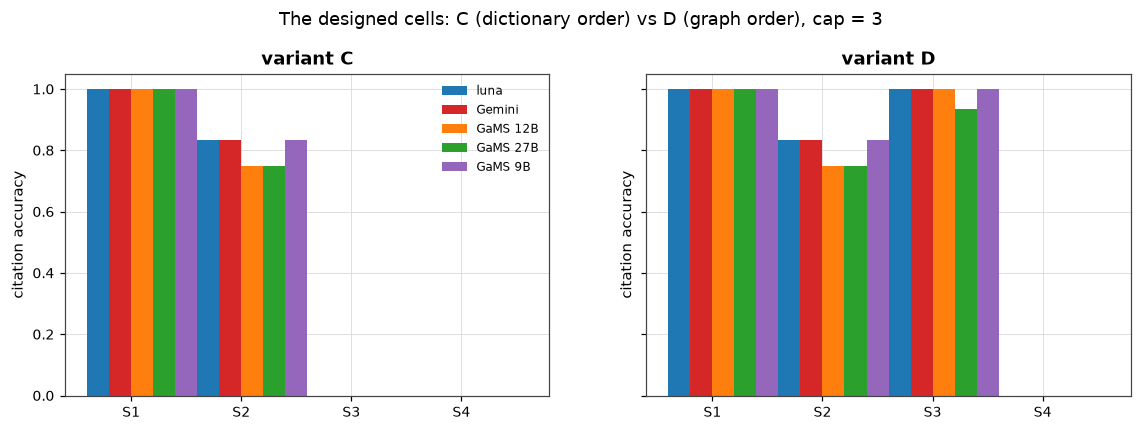

In [2]:
rows = []
for label, value in loaded.items():
    if value is None:
        continue
    _run_id, df = value
    d = df[df["variant"].isin(["C", "D"])]
    table = d.pivot_table(index="design_cell", columns="variant", values="correct", aggfunc="mean")
    for cell, row in table.iterrows():
        rows.append({"model": label, "cell": cell, "C": row["C"], "D": row["D"]})
cells_df = pd.DataFrame(rows)
pivot = cells_df.pivot(index="cell", columns="model", values="D")
print("D accuracy per cell and model (C is in the table below)")
display(cells_df.pivot_table(index="cell", columns="model", values=["C", "D"]).round(2))

sense = ["S1_shallow_cued", "S2_shallow_nocue", "S3_buried_cued", "S4_buried_nocue"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
models = [m for m in RUNS if loaded.get(m)]
colors = ["#1f77b4", "#d62728", "#ff7f0e", "#2ca02c", "#9467bd"]
for ax, variant in zip(axes, ["C", "D"], strict=True):
    x = np.arange(len(sense))
    for i, model in enumerate(models):
        vals = [
            cells_df[(cells_df["model"] == model) & (cells_df["cell"] == c)][variant].mean()
            for c in sense
        ]
        ax.bar(x + (i - 1.5) * 0.2, vals, width=0.2, color=colors[i], label=model)
    ax.set_xticks(x)
    ax.set_xticklabels([c.split("_")[0] for c in sense])
    ax.set_ylim(0, 1.05)
    ax.set_title(f"variant {variant}")
    ax.set_ylabel("citation accuracy")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("The designed cells: C (dictionary order) vs D (graph order), cap = 3", y=1.03)
al.save_figure(fig, "07_cells_cd")
plt.show()

> **Reading the chart.** C and D are identical in S1/S2 (the gold is visible, so
> order does not matter), C collapses to zero in S3/S4 (the gold is outside the
> cap by construction), and D recovers almost everything in S3 (the cue is
> present) but nothing in S4 (no cue -> the graph falls back to dictionary
> order). This is the payoff rule, cell by cell.

## What an oracle is - and why it can be exceeded

The Oracle row is **not a model**. It is the same pipeline with the gold sense
handed to the model (gold + neighbours, capped at 5). It answers: *if retrieval
and ranking were perfect, how good would the model's answer composition be?*
It is the **composition ceiling**, not a competitor.

Two consequences that confuse readers:

1. **The oracle is an upper bound in expectation, not a mathematical bound.**
   Its prompt is *different* from C/D (a shorter, gold-centred list), and a
   shorter list can make the model behave worse. So one run can show
   `D > oracle` (Gemini at full context: D 0.972 vs oracle 0.944; GaMS 9B on v2:
   D 0.86 vs oracle 0.84) without anything being broken.
2. **The informative quantity is `oracle - C/D`**: it is the composition error -
   the part no better retriever or ranker can fix. If the oracle were *far*
   below C/D, that would be a bug in the oracle context, not a result.

The per-cell oracle row for the v2 run is in the table below; the point to read
is that S3's oracle is 1.00 (the model can use the gold when it is shown) while
C is 0.00 (it is not shown) and D is ~1.00 (the graph puts it back).

In [3]:
oracle_rows = []
for label, value in loaded.items():
    if value is None:
        continue
    _run_id, df = value
    o = df[df["variant"] == "oracle"]
    for cell, value_ in o.groupby("design_cell")["correct"].mean().items():
        oracle_rows.append({"model": label, "cell": cell, "oracle": value_})
oracle_df = pd.DataFrame(oracle_rows)
if not oracle_df.empty:
    display(oracle_df.pivot(index="cell", columns="model", values="oracle").round(2))

model,GaMS 12B,GaMS 27B,GaMS 9B,Gemini,luna
cell,,,,,
R_antonym_disjoint,1.00,1.00,1.00,1.00,1.0
R_antonym_overlap,1.00,1.00,1.00,1.00,1.0
R_hypernym_overlap,1.00,1.00,1.00,1.00,1.0
R_synonym_disjoint,1.00,1.00,1.00,0.83,1.0
R_synonym_overlap,1.00,1.00,1.00,1.00,1.0
S1_shallow_cued,1.00,1.00,0.75,1.00,1.0
S2_shallow_nocue,0.83,0.83,0.75,1.00,1.0
S3_buried_cued,1.00,0.93,0.93,1.00,1.0
S4_buried_nocue,0.60,0.40,0.40,1.00,0.8


## Statistical comparison (C vs D per cell)

The counts are tiny (S1 = 4, S4 = 5), so only S3 should survive correction.
The test is the **exact McNemar** on the discordant pairs, with a paired
bootstrap CI for the difference and a Holm correction across the four sense
cells. The code is in `elexai.analysis.cell_comparison`.

In [4]:
for model in [m for m in RUNS if loaded.get(m)]:
    _run_id, df = loaded[model]
    rows = [al.cell_comparison(df, cell) for cell in sense]
    rows = [r for r in rows if r.get("n")]
    p_adj = al.holm_bonferroni([r["p"] for r in rows])
    for row, padj in zip(rows, p_adj, strict=True):
        row["p_holm"] = round(padj, 4)
    print(f"--- {model}")
    display(pd.DataFrame(rows)[["cell", "n", "C", "D", "diff", "first_only", "second_only", "p", "p_holm", "ci_low", "ci_high"]])

--- luna


,cell,n,C,D,diff,first_only,second_only,p,p_holm,ci_low,ci_high
0,S1_shallow_cued,4,1.000,1.000,0.0,0,0,1.000000,1.0000,0.0,0.0
1,S2_shallow_nocue,12,0.833,0.833,0.0,0,0,1.000000,1.0000,0.0,0.0
2,S3_buried_cued,15,0.000,1.000,1.0,0,15,0.000061,0.0002,1.0,1.0
3,S4_buried_nocue,5,0.000,0.000,0.0,0,0,1.000000,1.0000,0.0,0.0


--- Gemini


,cell,n,C,D,diff,first_only,second_only,p,p_holm,ci_low,ci_high
0,S1_shallow_cued,4,1.000,1.000,0.0,0,0,1.000000,1.0000,0.0,0.0
1,S2_shallow_nocue,12,0.833,0.833,0.0,0,0,1.000000,1.0000,0.0,0.0
2,S3_buried_cued,15,0.000,1.000,1.0,0,15,0.000061,0.0002,1.0,1.0
3,S4_buried_nocue,5,0.000,0.000,0.0,0,0,1.000000,1.0000,0.0,0.0


--- GaMS 12B


,cell,n,C,D,diff,first_only,second_only,p,p_holm,ci_low,ci_high
0,S1_shallow_cued,4,1.00,1.00,0.0,0,0,1.000000,1.0000,0.0,0.0
1,S2_shallow_nocue,12,0.75,0.75,0.0,0,0,1.000000,1.0000,0.0,0.0
2,S3_buried_cued,15,0.00,1.00,1.0,0,15,0.000061,0.0002,1.0,1.0
3,S4_buried_nocue,5,0.00,0.00,0.0,0,0,1.000000,1.0000,0.0,0.0


--- GaMS 27B


,cell,n,C,D,diff,first_only,second_only,p,p_holm,ci_low,ci_high
0,S1_shallow_cued,4,1.00,1.000,0.000,0,0,1.000000,1.0000,0.0,0.0
1,S2_shallow_nocue,12,0.75,0.750,0.000,0,0,1.000000,1.0000,0.0,0.0
2,S3_buried_cued,15,0.00,0.933,0.933,0,14,0.000122,0.0005,0.8,1.0
3,S4_buried_nocue,5,0.00,0.000,0.000,0,0,1.000000,1.0000,0.0,0.0


--- GaMS 9B


,cell,n,C,D,diff,first_only,second_only,p,p_holm,ci_low,ci_high
0,S1_shallow_cued,4,1.000,1.000,0.0,0,0,1.000000,1.0000,0.0,0.0
1,S2_shallow_nocue,12,0.833,0.833,0.0,0,0,1.000000,1.0000,0.0,0.0
2,S3_buried_cued,15,0.000,1.000,1.0,0,15,0.000061,0.0002,1.0,1.0
3,S4_buried_nocue,5,0.000,0.000,0.0,0,0,1.000000,1.0000,0.0,0.0


## The B repair: `--b-lemma`

Variant B searches the whole dictionary (131k definitions) and therefore often
retrieves a *different lemma* (the top-1 is the wrong lemma in 78 % of cases on
v1). `--b-lemma` restricts the search to the target lemma's own senses - the
"first restrict candidates, then rank" repair. If B's problem is scope, not the
model, this should close most of the gap.

In [5]:
pairs = {
    "luna": ("skeleton-cap3-v2", "skeleton-cap3-blemma-v2"),
    "GaMS 12B": ("gams3-12b-api-v2", "gams3-12b-api-blemma-v2"),
}
b_rows = []
for label, (full_name, lemma_name) in pairs.items():
    try:
        full_run = al.find_run(full_name)
        lemma_run = al.find_run(lemma_name)
    except KeyError:
        continue
    for run_id, tag in ((full_run, "B"), (lemma_run, "B-lemma")):
        cfg = yaml.safe_load((REPO / "runs" / run_id / "config.resolved.yaml").read_text(encoding="utf-8"))
        qpath = Path(cfg["questions_path"])
        if not qpath.is_absolute():
            qpath = REPO / qpath
        df = al.load_answers(run_id, questions_path=qpath)
        b = df[df["variant"] == "B"]
        for cell, acc in b.groupby("design_cell")["correct"].mean().items():
            b_rows.append({"model": label, "cell": cell, "kind": tag, "acc": acc})
b_df = pd.DataFrame(b_rows)
if not b_df.empty:
    print(b_df.pivot_table(index=["cell"], columns=["model", "kind"], values="acc").round(2))

model              GaMS 12B          luna        
kind                      B B-lemma     B B-lemma
cell                                             
R_antonym_disjoint     0.00    0.00  0.00    0.00
R_antonym_overlap      0.00    0.00  0.00    0.00
R_hypernym_overlap     0.50    0.50  0.50    0.50
R_synonym_disjoint     0.00    0.00  0.00    0.00
R_synonym_overlap      0.67    0.67  0.67    0.67
S1_shallow_cued        0.25    1.00  0.25    1.00
S2_shallow_nocue       0.25    0.75  0.25    0.83
S3_buried_cued         0.47    0.93  0.47    0.93
S4_buried_nocue        0.20    0.40  0.40    0.40


## Budget curve: cap 1 / 2 / 3

The v2 design fixes the primary regime at cap = 3. The budget curve checks that
the S3 effect is not an artefact of that single value: as the cap shrinks, C's
coverage collapses further while D's ranking can still recover the cued items.

variant          C     D
model    cap            
GaMS 12B 1    0.31  0.76
         2    0.43  0.78
         3    0.45  0.82
luna     1    0.31  0.76
         2    0.43  0.82
         3    0.47  0.86

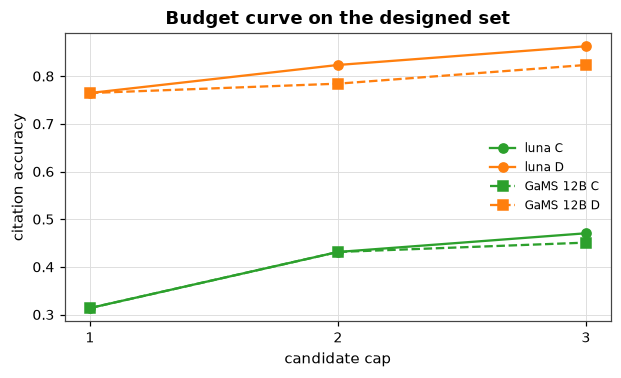

In [6]:
budget_rows = []
for model, names in {
    "luna": {1: "skeleton-cap1-v2", 2: "skeleton-cap2-v2", 3: "skeleton-cap3-v2"},
    "GaMS 12B": {1: "gams3-12b-api-cap1-v2", 2: "gams3-12b-api-cap2-v2", 3: "gams3-12b-api-v2"},
}.items():
    for cap, name in names.items():
        try:
            run_id = al.find_run(name)
        except KeyError:
            continue
        cfg = yaml.safe_load((REPO / "runs" / run_id / "config.resolved.yaml").read_text(encoding="utf-8"))
        qpath = Path(cfg["questions_path"])
        if not qpath.is_absolute():
            qpath = REPO / qpath
        df = al.load_answers(run_id, questions_path=qpath)
        for variant in ("C", "D"):
            acc = df[df["variant"] == variant]["correct"].mean()
            budget_rows.append({"model": model, "cap": cap, "variant": variant, "acc": acc})
budget = pd.DataFrame(budget_rows)
if not budget.empty:
    display(budget.pivot_table(index=["model", "cap"], columns="variant", values="acc").round(2))
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    for model, style in (("luna", "-o"), ("GaMS 12B", "--s")):
        for variant, color in (("C", "#2ca02c"), ("D", "#ff7f0e")):
            sub = budget[(budget["model"] == model) & (budget["variant"] == variant)].sort_values("cap")
            if not sub.empty:
                ax.plot(sub["cap"], sub["acc"], style, color=color, label=f"{model} {variant}")
    ax.set_xlabel("candidate cap")
    ax.set_ylabel("citation accuracy")
    ax.set_xticks([1, 2, 3])
    ax.legend(fontsize=8)
    ax.set_title("Budget curve on the designed set")
    al.save_figure(fig, "07_budget")
    plt.show()

## What this does and does not show

**Shows.** The graph is worth exactly what the payoff rule predicts: it changes
the answer when the gold sense is outside the visible list *and* the sentence
carries a distinctive cue, and nowhere else. The effect is large (S3: C 0 vs D
~1.0) and survives the exact test with Holm correction.

**Does not show.** That the graph is worth this much in real text. The S3
sentences were **built around a dictionary collocation**, so the cue is present
by construction; in naturally occurring text, cues may be rarer, weaker, or
paraphrased. The next step is therefore a **natural-sentence control**: a set of
corpus sentences with lexicographer-verified gold senses, scored with the same
cells.

**Other limits.** Questions are drafts until a lexicographer verifies them; N per
cell is small (S1 = 4, S4 = 5); the stemmer is a documented approximation; the
relation layer is dictionary-native only (the WordNet re-link is noisy); the
Lex model is not measured yet.